# Milestone M1: Dataset Download & Quality Audit
## Project: Recut Research Lab 01 — Advertising Consistency & Claim Verification

---

### 1. Research Objective
The objective of Milestone M1 is to conduct a rigorous, reproducible quality and integrity audit of the official **CyberAgent AdTEC (Ad-Consistency)** benchmark. This audit inspects technical data integrity, label distributions, duplicate instances, Japanese text character length properties, surface lexical overlap proxies, potential cross-split data leakage vectors, and establishes a standardized qualitative sample inspection protocol.

> [!IMPORTANT]
> **Core Scientific Distinctions**:
> - **Semantic Similarity**: Measures topical or geometric proximity in an embedding space.
> - **Semantic Consistency**: Evaluates whether an ad headline (`title`) is substantively supported by, aligned with, and accurately representative of its destination landing page (`lp_text`), avoiding misleading or unsubstantiated claims.
> - **Factual Verification / Entailment**: Requires rigorous external truth grounding (e.g., verifying empirical or clinical evidence).
> 
> **Scope Notice**: The CyberAgent AdTEC benchmark evaluates **binary consistency classification (`consistent` vs. `inconsistent`)** in Japanese search engine advertising. It is **NOT** a three-class factual claim-verification benchmark (e.g., Supports / Refutes / Not Enough Info) and does **NOT** evaluate medical, therapeutic, or clinical efficacy claims for skincare or cosmetic products.

### 2. Dataset Source and License
- **Benchmark**: CyberAgent AdTEC (*A Unified Benchmark for Evaluating Text Quality in Search Engine Advertising*, NAACL 2025)
- **Task Subset**: `ad-consistency`
- **Target Language**: Japanese (`ja`)
- **Application Domain**: Search engine sponsored advertisements
- **Official Repositories**: [Hugging Face Hub: cyberagent/AdTEC](https://huggingface.co/datasets/cyberagent/AdTEC) | [GitHub: CyberAgentAILab/AdTEC](https://github.com/CyberAgentAILab/AdTEC)
- **Dataset License**: **Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International (CC BY-NC-SA 4.0)**.
  * The dataset is strictly restricted to non-commercial research use.
  * Research software and evaluation tooling in `recut-research-lab` are licensed under the MIT License.
  * In compliance with research governance, all raw and processed dataset files are excluded from version control via `.gitignore`.

In [1]:
# Configure research workspace and load core recut_lab modules
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Ensure src/ is accessible on the Python search path
src_path = Path('../src').resolve()
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from recut_lab.data import load_adtec_dataset, PUBLISHED_SPLIT_COUNTS
from recut_lab.audit import (
    run_dataset_audit, format_audit_markdown, sample_qualitative_audit
)

# Configure Japanese research aesthetic palette
BG_COLOR = "#F7F3EA"       # Warm ivory
INDIGO_COLOR = "#33415C"   # Indigo (primary / consistent)
VERMILION = "#C65D4B"      # Vermilion (accent / inconsistent)
MATCHA = "#71816D"         # Matcha green (secondary / metrics)
MUTED_GRAY = "#8A8A86"     # Muted gray (gridlines / borders)

import matplotlib.pyplot as plt
import matplotlib as mpl

# Set font family fallback for Japanese text rendering and plot backgrounds
mpl.rcParams['font.sans-serif'] = [
    'Meiryo', 'Yu Gothic', 'MS Gothic', 'Noto Sans CJK JP', 
    'TakaoPGothic', 'DejaVu Sans', 'sans-serif'
]
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['figure.facecolor'] = BG_COLOR
mpl.rcParams['axes.facecolor'] = BG_COLOR


### 3. Dataset Loading & Split Verification
- **QUESTION**: Can the official upstream TSV files (`train.tsv`, `valid.tsv`, `test.tsv`) be loaded deterministically without data corruption, and do their row counts match published NAACL 2025 specifications exactly?
- **METHOD**: Load the raw TSV files via `recut_lab.data.load_adtec_dataset`, preserving the original UTF-8 Japanese text without truncation or normalization, and verify split sizes against `PUBLISHED_SPLIT_COUNTS`.

In [2]:
# Load official splits from local storage
data_dir = Path('../data/raw/adtec_consistency')
dataset = load_adtec_dataset(data_dir)

# Verify split row counts against official published benchmark figures
verification_results = dataset.verify_split_counts()
verification_df = pd.DataFrame([
    {
        'Split': split_name,
        'Actual Rows': info['actual'],
        'Published Rows': info['expected'],
        'Row Match': '[VERIFIED] MATCH' if info['match'] else '[WARNING] MISMATCH',
        'Difference': info['difference'],
    }
    for split_name, info in verification_results.items()
])
display(verification_df)

,Split,Actual Rows,Published Rows,Row Match,Difference
0,train,10635,10635,[VERIFIED] MATCH,0
1,valid,945,945,[VERIFIED] MATCH,0
2,test,970,970,[VERIFIED] MATCH,0


- **INTERPRETATION**:
All three splits match the published NAACL 2025 benchmark counts exactly (Train: 10,635; Valid: 945; Test: 970; Total: 12,550 rows). The raw dataset is stored and parsed as authentic UTF-8 tab-separated values without format degradation.

### 4. Schema Inspection
- **QUESTION**: Are all expected columns present with valid data types across all splits?
- **METHOD**: Inspect column names, column counts, pandas data types, and DataFrame dimensions across `train`, `valid`, and `test`.

In [3]:
# Inspect structural schema across all dataset splits
schema_data = []
for split_name in ['train', 'valid', 'test']:
    df_split = dataset.get_split(split_name)
    schema_data.append({
        'Split': split_name,
        'Dimensions': df_split.shape,
        'Columns': list(df_split.columns),
        'Data Types': {col: str(dtype) for col, dtype in df_split.dtypes.items()},
    })
display(pd.DataFrame(schema_data))

,Split,Dimensions,Columns,Data Types
0,train,"(10635, 3)","[label, lp_text, title]","{'label': 'object', 'lp_text': 'object', 'titl..."
1,valid,"(945, 3)","[label, lp_text, title]","{'label': 'object', 'lp_text': 'object', 'titl..."
2,test,"(970, 3)","[label, lp_text, title]","{'label': 'object', 'lp_text': 'object', 'titl..."


- **INTERPRETATION**:
Each split strictly contains the three expected fields: `label` (binary categorical string), `lp_text` (landing-page text), and `title` (advertising headline). No extraneous identifiers or missing columns exist.

### 5. Missing and Empty Value Audit
- **QUESTION**: Do any rows contain null (NaN), empty string `""`, or whitespace-only values?
- **METHOD**: Scan all fields across each split using `isnull()`, string length checks `(col == "")`, and whitespace stripping `((col != "") & (col.str.strip() == ""))`.

In [4]:
# Audit missing values, empty strings, and whitespace-only entries
missing_records = []
for split_name in ['train', 'valid', 'test']:
    df_split = dataset.get_split(split_name)
    for col in ['label', 'lp_text', 'title']:
        series = df_split[col].astype(str)
        null_count = int(df_split[col].isnull().sum())
        empty_count = int((series == '').sum())
        ws_only_count = int(((series != '') & (series.str.strip() == '')).sum())
        missing_records.append({
            'Split': split_name,
            'Column': col,
            'Null Count': null_count,
            'Empty String Count': empty_count,
            'Whitespace-Only Count': ws_only_count,
        })
display(pd.DataFrame(missing_records))

,Split,Column,Null Count,Empty String Count,Whitespace-Only Count
0,train,label,0,0,0
1,train,lp_text,0,0,0
2,train,title,0,0,0
3,valid,label,0,0,0
4,valid,lp_text,0,0,0
5,valid,title,0,0,0
6,test,label,0,0,0
7,test,lp_text,0,0,0
8,test,title,0,0,0


- **INTERPRETATION**:
Across all 12,550 rows in the benchmark, there are **0 null values, 0 empty strings, and 0 whitespace-only fields**. The dataset exhibits high technical completeness.

### 6. Label Distribution & Class Imbalance Analysis
- **QUESTION**: What are the class proportions for `consistent` vs. `inconsistent` across splits, and is there evidence of label distribution shift between development and test data?
- **METHOD**: Compute absolute class counts, percentages, and the majority-to-minority class imbalance ratio (`majority_count / minority_count`).

,Split,Total Rows,Consistent (N),Consistent (%),Inconsistent (N),Inconsistent (%),Majority Class,Imbalance Ratio
0,train,10635,6256,58.82%,4379,41.18%,consistent,1.43:1
1,valid,945,588,62.22%,357,37.78%,consistent,1.65:1
2,test,970,730,75.26%,240,24.74%,consistent,3.04:1


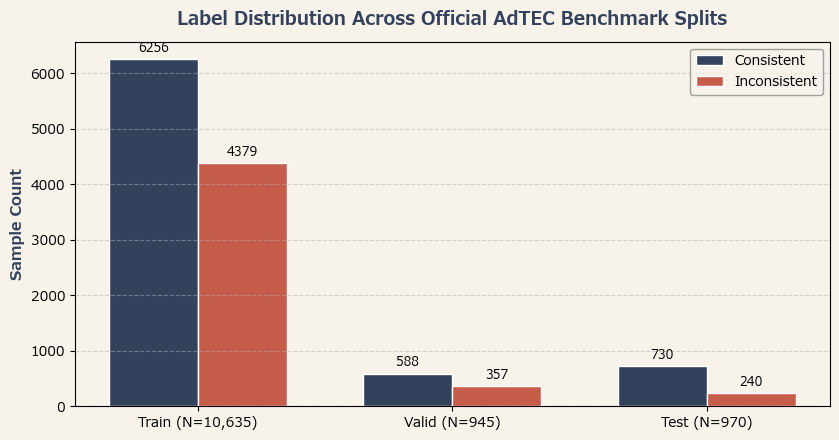

In [5]:
# Calculate label distributions and class imbalance ratios
label_stats = []
for split_name in ['train', 'valid', 'test']:
    df_split = dataset.get_split(split_name)
    counts = df_split['label'].value_counts().to_dict()
    total = len(df_split)
    c_count = counts.get('consistent', 0)
    i_count = counts.get('inconsistent', 0)
    ratio = round(c_count / max(i_count, 1), 2)
    label_stats.append({
        'Split': split_name,
        'Total Rows': total,
        'Consistent (N)': c_count,
        'Consistent (%)': f'{c_count / total * 100:.2f}%',
        'Inconsistent (N)': i_count,
        'Inconsistent (%)': f'{i_count / total * 100:.2f}%',
        'Majority Class': 'consistent',
        'Imbalance Ratio': f'{ratio}:1',
    })

display(pd.DataFrame(label_stats))

# Visualize label distribution using grouped bar chart
splits = ['train', 'valid', 'test']
consistent_counts = [dataset.get_split(s)['label'].value_counts().get('consistent', 0) for s in splits]
inconsistent_counts = [dataset.get_split(s)['label'].value_counts().get('inconsistent', 0) for s in splits]

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=100)
x_indices = np.arange(len(splits))
bar_width = 0.35

bars_c = ax.bar(x_indices - bar_width/2, consistent_counts, bar_width, label='Consistent', color=INDIGO_COLOR, edgecolor='white')
bars_i = ax.bar(x_indices + bar_width/2, inconsistent_counts, bar_width, label='Inconsistent', color=VERMILION, edgecolor='white')

ax.set_ylabel('Sample Count', fontsize=11, fontweight='bold', color=INDIGO_COLOR)
ax.set_title('Label Distribution Across Official AdTEC Benchmark Splits', fontsize=13, fontweight='bold', pad=12, color=INDIGO_COLOR)
ax.set_xticks(x_indices)
ax.set_xticklabels(['Train (N=10,635)', 'Valid (N=945)', 'Test (N=970)'], fontsize=10)
ax.legend(frameon=True, facecolor=BG_COLOR, edgecolor=MUTED_GRAY)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate bar values
for bar in bars_c + bars_i:
    height = bar.get_height()
    ax.annotate(f'{height}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

- **INTERPRETATION**:
1. **Development Class Proportions**: In the `train` split, `consistent` instances constitute **58.82%** (6,256 rows) and `inconsistent` constitute **41.18%** (4,379 rows), yielding an imbalance ratio of **1.43:1**. The `valid` split exhibits comparable proportions (62.22% vs. 37.78%, ratio **1.65:1**).
2. **Substantial Distribution Shift in Test**: In the official `test` split, the proportion of `consistent` instances rises to **75.26%** (730 rows), whereas `inconsistent` drops to **24.74%** (240 rows), increasing the imbalance ratio to **3.04:1**.
3. **Metric Implications**: Because majority-class guessing on the test split yields an uncalibrated 75.26% Accuracy, Accuracy alone is misleading. Model evaluation protocols must prioritize **Macro-F1** and per-class recall to ensure reliable detection of minority `inconsistent` advertisements.

### 7. Duplicate and Data Leakage Analysis
- **QUESTION**: How prevalent are exact duplicate rows, duplicate `(title, lp_text)` pairs, identical text pairs with conflicting labels, and cross-split overlaps?
- **METHOD**: Quantify exact row duplicates, pair duplicates, unique landing pages, and conflicting labels (`groupby(['title', 'lp_text'])['label'].nunique() > 1`). Evaluate cross-split overlap for exact pairs, normalized pairs (NFKC Unicode normalization with whitespace collapsing), and landing page text sharing.

,Split,Exact Row Duplicates,"Duplicate (T, LP) Pairs",Duplicate Titles,Duplicate LP Texts,Conflicting Label Pairs,Conflicting Affected Rows
0,train,0,92,200,9715,92,184
1,valid,0,6,10,917,6,12
2,test,64,68,80,795,4,13


,Split Comparison,"Exact Pair Overlap (N, %)","Normalized Pair Overlap (N, %)","Shared Unique LPs (N, %)","Shared Unique Titles (N, %)"
0,train_vs_valid,0 (0.0%),0 (0.0%),13 (46.43% of valid),0 (0.0% of valid)
1,train_vs_test,0 (0.0%),0 (0.0%),54 (30.86% of test),0 (0.0% of test)
2,valid_vs_test,0 (0.0%),0 (0.0%),3 (1.71% of test),0 (0.0% of test)


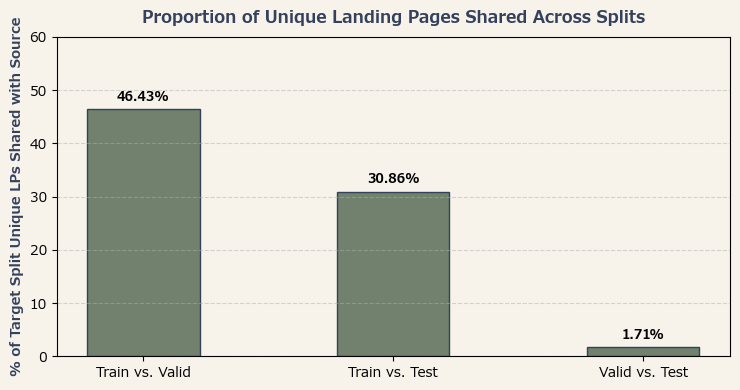

In [6]:
# Execute comprehensive duplicate and leakage audit
audit_summary = run_dataset_audit(dataset)

# 1. Intra-split duplicate and conflicting label table
duplicate_table = []
for split_name, report in audit_summary.splits.items():
    dup = report.duplicates
    duplicate_table.append({
        'Split': split_name,
        'Exact Row Duplicates': dup.exact_duplicate_rows,
        'Duplicate (T, LP) Pairs': dup.duplicate_title_lp_pairs,
        'Duplicate Titles': dup.duplicate_titles,
        'Duplicate LP Texts': dup.duplicate_lp_texts,
        'Conflicting Label Pairs': dup.conflicting_label_pairs,
        'Conflicting Affected Rows': dup.conflicting_label_sample_count,
    })
display(pd.DataFrame(duplicate_table))

# 2. Cross-split overlap and leakage table
leakage_table = []
for ov in audit_summary.cross_split_overlaps:
    leakage_table.append({
        'Split Comparison': ov.pair_name,
        'Exact Pair Overlap (N, %)': f'{ov.exact_pair_overlap_count} ({ov.exact_pair_overlap_pct_of_split2}%)',
        'Normalized Pair Overlap (N, %)': f'{ov.normalized_pair_overlap_count} ({ov.normalized_pair_overlap_pct_of_split2}%)',
        'Shared Unique LPs (N, %)': f'{ov.lp_overlap_count} ({ov.lp_overlap_pct_of_split2}% of {ov.split2_name})',
        'Shared Unique Titles (N, %)': f'{ov.title_overlap_count} ({ov.title_overlap_pct_of_split2}% of {ov.split2_name})',
    })
display(pd.DataFrame(leakage_table))

# Visualize shared landing page proportions
fig, ax = plt.subplots(figsize=(7.5, 4), dpi=100)
comparison_labels = ['Train vs. Valid', 'Train vs. Test', 'Valid vs. Test']
shared_lp_percentages = [ov.lp_overlap_pct_of_split2 for ov in audit_summary.cross_split_overlaps]

bars = ax.bar(comparison_labels, shared_lp_percentages, color=MATCHA, width=0.45, edgecolor=INDIGO_COLOR)
ax.set_ylabel('% of Target Split Unique LPs Shared with Source', fontsize=10, fontweight='bold', color=INDIGO_COLOR)
ax.set_title('Proportion of Unique Landing Pages Shared Across Splits', fontsize=12, fontweight='bold', pad=10, color=INDIGO_COLOR)
ax.set_ylim(0, 60)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    val = bar.get_height()
    ax.annotate(f'{val:.2f}%', xy=(bar.get_x() + bar.get_width()/2, val),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

- **INTERPRETATION**:
1. **Exact Pair Overlap**: There is **0.0% exact (title, lp_text) pair overlap** between `train` and `valid`/`test`. No identical input pairs leak across split boundaries.
2. **Test Set Exact Duplicates**: The official `test.tsv` contains **64 exact duplicate rows** (identical title, landing page, and label). In accordance with standard benchmark preservation protocols, these rows are documented rather than silently discarded.
3. **Identical Text Pairs with Conflicting Labels**: In `train`, there are **92 distinct (title, lp_text) pairs** (affecting 184 rows) that appear with contradictory labels (one occurrence labeled `consistent`, another labeled `inconsistent`). In `valid`, there are 6 such pairs (12 rows); in `test`, there are 4 pairs (13 rows). Contradictory labels on identical text pairs prevent any deterministic pair-only classifier from achieving 100% training accuracy on these instances. Note: The benchmark dataset does not include annotator identifiers, so this represents observed label contradiction rather than proven inter-annotator disagreement.
4. **Shared Landing Pages Across Splits**: Out of 28 unique landing pages in `valid`, **13 (46.43%)** also appear in `train`. Out of 175 unique landing pages in `test`, **54 (30.86%)** also appear in `train`. This reflects standard search advertising structure (multiple ad variants driving traffic to a single corporate or campaign landing page). However, this creates a potential group-structure confounding risk: models evaluating ad consistency may partially rely on familiar landing page domains rather than generalizing to unseen web properties. Evaluating this requires LP-disjoint grouped splits in future research.

### 8. Text Character Length Statistics
- **QUESTION**: What are the character length distributions of ad headlines (`title`) and landing pages (`lp_text`), and how do they vary across splits and labels?
- **METHOD**: Measure character length using Unicode code points. Compute descriptive statistics: Min, P25, Median, Mean, P75, P95, Max, Standard Deviation, and Interquartile Range (IQR).

,Split,Field,Min,P25,Median,Mean,P75,P95,Max,Std,IQR
0,train,Title,3,13.0,16.0,26.85,44.0,47.0,166,15.54,31.0
1,train,LP Text,10,76.0,112.0,112.70,145.0,183.0,393,46.21,69.0
2,valid,Title,7,13.0,15.0,26.17,44.0,46.0,53,15.24,31.0
3,valid,LP Text,27,68.0,69.0,75.58,93.0,107.0,173,20.56,25.0
4,test,Title,5,13.0,15.0,25.03,42.0,47.0,137,17.51,29.0
5,test,LP Text,19,73.0,95.0,97.74,118.0,154.0,247,29.44,45.0


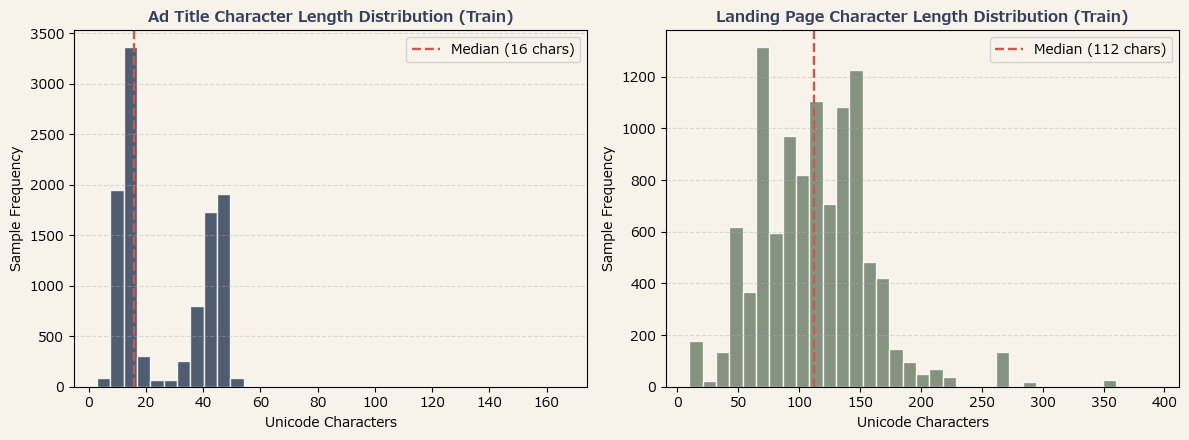

In [7]:
# Extract character length statistics across splits and text fields
length_rows = []
for split_name, report in audit_summary.splits.items():
    for field_name, stats in [('Title', report.text_characteristics.overall_title),
                              ('LP Text', report.text_characteristics.overall_lp)]:
        length_rows.append({
            'Split': split_name,
            'Field': field_name,
            'Min': stats.min,
            'P25': stats.p25,
            'Median': stats.median,
            'Mean': stats.mean,
            'P75': stats.p75,
            'P95': stats.p95,
            'Max': stats.max,
            'Std': stats.std,
            'IQR': stats.iqr,
        })
display(pd.DataFrame(length_rows))

# Plot character length distributions for Train split
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
train_df = dataset.train

# Headline title character length
axes[0].hist(train_df['title'].str.len(), bins=35, color=INDIGO_COLOR, alpha=0.85, edgecolor='white')
axes[0].axvline(train_df['title'].str.len().median(), color=VERMILION, linestyle='--', linewidth=1.75, label='Median (16 chars)')
axes[0].set_title('Ad Title Character Length Distribution (Train)', fontsize=11, fontweight='bold', color=INDIGO_COLOR)
axes[0].set_xlabel('Unicode Characters', fontsize=10)
axes[0].set_ylabel('Sample Frequency', fontsize=10)
axes[0].legend(frameon=True, facecolor=BG_COLOR)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# Landing page character length
axes[1].hist(train_df['lp_text'].str.len(), bins=35, color=MATCHA, alpha=0.85, edgecolor='white')
axes[1].axvline(train_df['lp_text'].str.len().median(), color=VERMILION, linestyle='--', linewidth=1.75, label='Median (112 chars)')
axes[1].set_title('Landing Page Character Length Distribution (Train)', fontsize=11, fontweight='bold', color=INDIGO_COLOR)
axes[1].set_xlabel('Unicode Characters', fontsize=10)
axes[1].set_ylabel('Sample Frequency', fontsize=10)
axes[1].legend(frameon=True, facecolor=BG_COLOR)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

- **INTERPRETATION**:
1. **Ad Titles**: Tightly constrained around a median of **16 characters** (P25 = 13.0, P75 = 44.0, IQR = 31.0), reflecting standard headline limits in Japanese search advertising campaigns.
2. **Landing Page Text**: Substantially longer and more dispersed, with a median of **112 characters** in `train` (P25 = 76.0, P75 = 145.0, Max = 393). Noticeable variance exists across splits: in `valid`, median LP length is **69 characters** (IQR = 25.0).
3. **Tokenization Considerations**: Japanese text is written without whitespace delimiters between words. Measuring length via Unicode character counts avoids arbitrary word segmentation biases.

### 9. Lexical Relationship & Surface Overlap Analysis
- **QUESTION**: What is the degree of surface character overlap between ad titles and landing pages, and does character n-gram similarity clearly separate consistent from inconsistent pairs?
- **METHOD**: Compute exploratory surface overlap proxies: character unigram Jaccard, character bigram Jaccard, character trigram Jaccard, and length ratio `len(title) / len(lp_text)`. Analyze distributions stratified by class label.

,Split,Char Jaccard (Med / Mean),Bigram Jaccard (Med / Mean),Trigram Jaccard (Med / Mean),Title/LP Length Ratio (Med / Mean)
0,train,0.1449 / 0.1514,0.0533 / 0.0608,0.0286 / 0.0374,0.2323 / 0.2952
1,valid,0.1176 / 0.1268,0.0396 / 0.0475,0.0222 / 0.0306,0.2319 / 0.3893
2,test,0.1127 / 0.1283,0.0405 / 0.0514,0.0206 / 0.0330,0.1934 / 0.2849


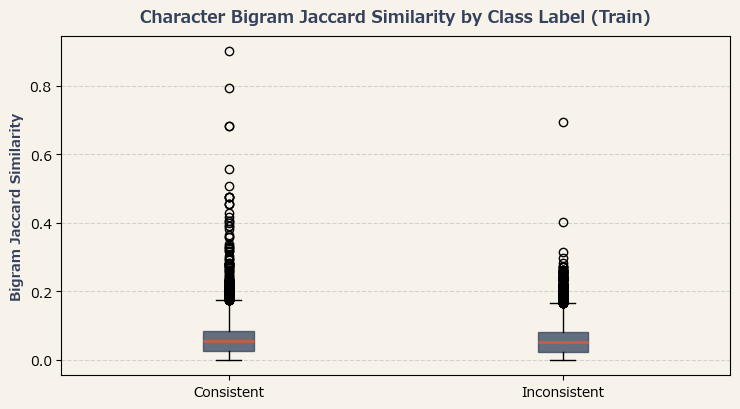

In [8]:
# Compute and display summary lexical overlap proxies
lexical_summary_rows = []
for split_name, report in audit_summary.splits.items():
    lex = report.lexical_relationships
    lexical_summary_rows.append({
        'Split': split_name,
        'Char Jaccard (Med / Mean)': f'{lex.char_jaccard_median:.4f} / {lex.char_jaccard_mean:.4f}',
        'Bigram Jaccard (Med / Mean)': f'{lex.bigram_jaccard_median:.4f} / {lex.bigram_jaccard_mean:.4f}',
        'Trigram Jaccard (Med / Mean)': f'{lex.trigram_jaccard_median:.4f} / {lex.trigram_jaccard_mean:.4f}',
        'Title/LP Length Ratio (Med / Mean)': f'{lex.length_ratio_median:.4f} / {lex.length_ratio_mean:.4f}',
    })
display(pd.DataFrame(lexical_summary_rows))

# Stratify character bigram Jaccard by label on Train split
from recut_lab.audit import extract_ngrams

train_df_lex = dataset.train.copy()
def compute_row_bigram_jaccard(row):
    b_title = extract_ngrams(str(row['title']), 2)
    b_lp = extract_ngrams(str(row['lp_text']), 2)
    union_b = b_title.union(b_lp)
    return len(b_title.intersection(b_lp)) / max(len(union_b), 1)

train_df_lex['bigram_jaccard'] = train_df_lex.apply(compute_row_bigram_jaccard, axis=1)

fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=100)
box_data = [
    train_df_lex[train_df_lex['label'] == 'consistent']['bigram_jaccard'],
    train_df_lex[train_df_lex['label'] == 'inconsistent']['bigram_jaccard'],
]
bp = ax.boxplot(
    box_data, tick_labels=['Consistent', 'Inconsistent'], patch_artist=True,
    boxprops=dict(facecolor=INDIGO_COLOR, color=INDIGO_COLOR, alpha=0.75),
    medianprops=dict(color=VERMILION, linewidth=2.0)
)

ax.set_title('Character Bigram Jaccard Similarity by Class Label (Train)', fontsize=12, fontweight='bold', pad=10, color=INDIGO_COLOR)
ax.set_ylabel('Bigram Jaccard Similarity', fontsize=10, fontweight='bold', color=INDIGO_COLOR)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- **INTERPRETATION**:
1. **Low Overall Surface Overlap**: Character bigram Jaccard similarity is low across all splits (median **0.0396 – 0.0533**; mean 0.0475 – 0.0608). Trigram overlap is even lower (median **0.0206 – 0.0286**).
2. **Impact of Length Asymmetry**: Because landing-page text is on average 3–4 times longer than the headline (median length ratio ~0.23), set union sizes are dominated by landing-page characters, naturally depressing Jaccard scores.
3. **Descriptive Nature of Overlap**: While `consistent` pairs exhibit marginally higher median overlap than `inconsistent` pairs, the distributions overlap substantially. Surface lexical matching alone cannot resolve consistency, as inconsistent pairs frequently share broad brand or navigational terms while diverging on specific promises or constraints.

### 10. Qualitative Sample Inspection Protocol
- **QUESTION**: How do authentic Japanese title and landing page pairs appear qualitatively, and how can researchers systematically audit ambiguous cases without prior bias?
- **METHOD**: Deterministically sample (seed = 42) **10 consistent and 10 inconsistent pairs from `train` and `valid` exclusively** (the test set is NEVER accessed for qualitative review). Preserve complete, un-truncated Japanese text and structure an audit table with unpopulated diagnostic fields: `topic_relevance`, `direct_support`, `potential_contradiction`, `insufficient_evidence`, `reviewer_notes`.

In [9]:
# Generate deterministic 20-sample qualitative audit table from Train and Valid
qualitative_samples = sample_qualitative_audit(dataset, n_per_class=10, random_seed=42)

# Display the first 8 samples for qualitative inspection
display(qualitative_samples[['sample_id', 'split', 'original_label', 'title', 'lp_text']].head(8))

print(f'[+] Successfully sampled {len(qualitative_samples)} instances (10 consistent, 10 inconsistent).')
print('    Diagnostic audit columns initialized empty: topic_relevance, direct_support, potential_contradiction, insufficient_evidence, reviewer_notes.')

,sample_id,split,original_label,title,lp_text
0,audit_001,train,consistent,結婚式場相談はブライダル埼玉,ゼクシィ相談カウンターで、結婚準備[結婚式会場、二次会会場、フォトウエディング、和婚、指輪]...
1,audit_002,train,inconsistent,【ライズ】サポート保険,入院や手術経験のある方も入りやすいオリックス生命の終身保険ライズ・サポート・プラスのご紹介です。
2,audit_003,train,inconsistent,帯広＆大分県日田市アパート,大分県日田市で賃貸物件を探すなら【スマホでCHINTAI】賃貸アパート・マンションなど不動産...
3,audit_004,train,consistent,オリックスライズは？,貯蓄性のある死亡保険なら、万が一にも、未来への備えにも。終身保険RISEライズのご紹介です。
4,audit_005,train,consistent,高額になる場合もある先進医療も保障する先進医療保険。保険料は加入時から上がりません,医療保険CURE Next[キュア・ネクスト]七大生活習慣病に特に手厚い医療保険(入院保険)...
5,audit_006,train,consistent,おすすめダイソン温風扇風機,扇風機・サーキュレーターを買うならジャパネット公式サイト！分割金利手数料はジャパネットが負担...
6,audit_007,train,inconsistent,持病がある方メディケア生命告知義務違反を見つけよう！お手頃な保険料、サポート体制も充実。,くらべればメディケア生命！医療保険も死亡保険も！メディケア生命保険の一生涯保険料があがらない...
7,audit_008,valid,consistent,cocaのカーディガンなら,コカ(coca)はこちら。丸井（マルイ）が運営するネット通販では人気ブランドを豊富に品揃え。...


[+] Successfully sampled 20 instances (10 consistent, 10 inconsistent).
    Diagnostic audit columns initialized empty: topic_relevance, direct_support, potential_contradiction, insufficient_evidence, reviewer_notes.


- **INTERPRETATION**:
1. **Preservation of Original Content**: Japanese headlines and landing pages are preserved in their authentic, un-truncated form, allowing complete context inspection.
2. **Unbiased Diagnostic Setup**: All manual diagnostic fields remain empty (`""`), preventing automated model bias from influencing human review.
3. **Split Protection**: The official test set remains completely unexposed, strictly adhering to research integrity protocol.

### 11. Findings and Scientific Limitations

#### Verified Findings [VERIFIED]
1. **Complete Split Integrity**: All 12,550 rows match published NAACL 2025 counts exactly; zero nulls, zero empty strings, and zero whitespace-only fields exist.
2. **Zero Direct Pair Leakage**: Zero exact `(title, lp_text)` pairs overlap across split boundaries (0.0%).
3. **Distribution Shift in Test**: The proportion of `consistent` instances increases from 58.82% in `train` to 75.26% in `test`, requiring Macro-F1 evaluation.
4. **Landing Page Cluster Sharing**: 46.43% of `valid` unique LPs (13 of 28) and 30.86% of `test` unique LPs (54 of 175) are shared with `train`.
5. **Contradictory Pair Labels**: 92 identical `(title, lp_text)` pairs in `train` carry contradictory labels, presenting an upper bound on deterministic pair-only accuracy.
6. **Test Set Duplicates**: 64 exact duplicate rows exist within the official `test` set.

#### Methodological & Scientific Limitations [ASSUMED / INFERRED]
1. **Editorial Quality vs. Factual Grounding**: AdTEC labels represent search advertising editorial relevance guidelines, not rigorous clinical or scientific factual verification.
2. **No Medical Claims Evaluation**: The dataset does not verify healthcare, medical, or clinical skincare efficacy claims.
3. **Surface Overlap Proxy Limits**: Low character n-gram Jaccard scores are descriptive and influenced by text length asymmetry; they do not imply that semantic models are automatically superior without experimental validation.

### 12. Research Questions for Subsequent Milestones

- **RQ1 (Group-Disjoint Evaluation)**: How much does model performance degrade when evaluating on landing pages strictly unseen during training compared to the standard split?
- **RQ2 (Lexical Overlap Illusion Hypothesis)**: Do bag-of-words and surface n-gram classifiers disproportionately produce false positives when headlines and landing pages share high vocabulary overlap without predicate agreement?
- **RQ3 (Evidence Sentence Selection Hypothesis)**: Does segmenting Japanese landing pages into sentence units and selecting top-K salient passages improve classification accuracy or inference efficiency over full-document truncation?
- **RQ4 (Domain Transfer to Recut)**: What is the zero-shot performance drop when transferring models trained on search advertising headlines to generated social and e-commerce promotional copy in Recut product verticals?